In [ ]:
from tqdm import tqdm
import os
import torch
import torch.nn as nn
import pickle

from torch.utils.data import DataLoader, random_split
from torchvision import datasets
from torchvision.models import densenet121, DenseNet121_Weights
import os
import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import (
    inception_v3, Inception_V3_Weights,
    resnet50, ResNet50_Weights,
    densenet121, DenseNet121_Weights,
    efficientnet_b0, EfficientNet_B0_Weights,
    swin_t, Swin_T_Weights
)

class BinaryClassifierBase(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return self.model(x)

In [ ]:
class DenseNet121Binary(BinaryClassifierBase):
    def __init__(self):
        super().__init__()
        weights = DenseNet121_Weights.DEFAULT
        self.model = densenet121(weights=weights)
        in_features = self.model.classifier.in_features
        self.model.classifier = nn.Sequential(
            nn.Linear(in_features, 1),
            nn.Sigmoid()
        )


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from PIL import Image
import os

root = "/content/drive/MyDrive/Classification/Bt_training_and_testing/Training_and_Validation_resized_256 (copy)"

for folder, _, files in os.walk(root):
    for file in files:
        path = os.path.join(folder, file)
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            print("Deleting:", path)
            os.remove(path)

Deleting: /content/drive/MyDrive/Classification/Bt_training_and_testing/Training_and_Validation_resized_256 (copy)/b_cancer/image27_804_.png


In [ ]:
# ------------------------
# Paths & Setup
# ------------------------
data_dir = "/content/drive/MyDrive/Classification/Bt_training_and_testing/Training_and_Validation_resized_256 (copy)"

checkpoint_dir = "/content/drive/MyDrive/Classification/Weights/DenseNet121"
os.makedirs(checkpoint_dir, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------
# Model & Transform
# ------------------------
weights = DenseNet121_Weights.DEFAULT
transform = weights.transforms()


class DenseNetBinary(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = densenet121(weights=None)

        in_features = self.model.classifier.in_features

        self.model.classifier = nn.Sequential(
            nn.Linear(in_features, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)


model = DenseNetBinary().to(device)

# ------------------------
# Dataset & Dataloader
# ------------------------
full_dataset = datasets.ImageFolder(
    root=data_dir,
    transform=transform
)

# Split 80/20
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_dataset,
    [train_size, val_size]
)

batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

# ------------------------
# Loss & Optimizer
# ------------------------
criterion = nn.BCELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

# ------------------------
# Training Setup
# ------------------------
num_epochs = 50

best_val_loss = float('inf')

history = {
    "epoch": [],
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

print(f"Device: {device}")
print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of validation samples: {len(val_dataset)}")
print(f"Total epochs: {num_epochs}")
print(f"Checkpoint directory: {checkpoint_dir}")

Device: cuda
Number of training samples: 2364
Number of validation samples: 591
Total epochs: 50
Checkpoint directory: /content/drive/MyDrive/Classification/Weights/DenseNet121


In [ ]:
# ------------------------
# Training Loop
# ------------------------

for epoch in tqdm(range(1, num_epochs + 1), desc="Epochs"):

    # ============================================================
    # TRAINING
    # ============================================================
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.float().unsqueeze(1).to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item() * labels.size(0)

        # Predictions
        preds = (outputs > 0.5).float()

        correct += (preds == labels).sum().item()
        total += labels.size(0)

    # Epoch training metrics
    train_loss = running_loss / total
    train_acc = correct / total


    # ============================================================
    # VALIDATION
    # ============================================================
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.float().unsqueeze(1).to(device)

            # Forward pass
            outputs = model(images)

            # Validation loss
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            # Predictions
            preds = (outputs > 0.5).float()

            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    # Epoch validation metrics
    val_loss /= val_total
    val_acc = val_correct / val_total


    # ============================================================
    # STORE HISTORY
    # ============================================================
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)


    # ============================================================
    # SAVE WEIGHTS AFTER EVERY EPOCH
    # ============================================================

    epoch_checkpoint_path = os.path.join(
        checkpoint_dir,
        f"epoch_{epoch:02d}_weights.pth"
    )

    torch.save(
        model.state_dict(),
        epoch_checkpoint_path
    )


    # ============================================================
    # SAVE COMPLETE CHECKPOINT
    # ============================================================
    # This is useful if you want to RESUME training later.

    epoch_checkpoint_full_path = os.path.join(
        checkpoint_dir,
        f"epoch_{epoch:02d}_checkpoint.pth"
    )

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc
        },
        epoch_checkpoint_full_path
    )


    # ============================================================
    # SAVE BEST MODEL
    # ============================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_path = os.path.join(
            checkpoint_dir,
            "best_weights.pth"
        )

        torch.save(
            model.state_dict(),
            best_model_path
        )

        print(
            f"\n✅ New best model saved "
            f"(Epoch {epoch}, Val Loss = {val_loss:.4f})"
        )


    # ============================================================
    # SAVE TRAINING HISTORY AFTER EVERY EPOCH
    # ============================================================

    history_path = os.path.join(
        checkpoint_dir,
        "training_history.pkl"
    )

    with open(history_path, "wb") as f:
        pickle.dump(history, f)


    # ============================================================
    # PRINT EPOCH RESULTS
    # ============================================================

    print(
        f"Epoch {epoch:2d}: "
        f"Train Loss: {train_loss:.4f}, "
        f"Train Acc: {train_acc:.4f}, "
        f"Val Loss: {val_loss:.4f}, "
        f"Val Acc: {val_acc:.4f}"
    )

print("\n" + "=" * 60)
print("TRAINING COMPLETED")
print("=" * 60)
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"All epoch weights saved in:")
print(checkpoint_dir)

Epochs:   0%|          | 0/50 [00:00<?, ?it/s]


✅ New best model saved (Epoch 1, Val Loss = 0.5774)


Epochs:   2%|▏         | 1/50 [00:47<38:46, 47.47s/it]

Epoch  1: Train Loss: 0.4847, Train Acc: 0.7644, Val Loss: 0.5774, Val Acc: 0.7513


Epochs:   4%|▍         | 2/50 [01:29<35:31, 44.40s/it]

...

Epoch 48: Train Loss: 0.0003, Train Acc: 1.0000, Val Loss: 0.2560, Val Acc: 0.9408


Epochs:  98%|█████████▊| 49/50 [36:10<00:49, 49.24s/it]

Epoch 49: Train Loss: 0.0002, Train Acc: 1.0000, Val Loss: 0.2556, Val Acc: 0.9475


Epochs: 100%|██████████| 50/50 [37:02<00:00, 44.46s/it]

Epoch 50: Train Loss: 0.0197, Train Acc: 0.9924, Val Loss: 0.5027, Val Acc: 0.8613

TRAINING COMPLETED
Best Validation Loss: 0.1985
All epoch weights saved in:
/content/drive/MyDrive/Classification/Weights/DenseNet121


In [ ]:
import os
import torch
import torch.nn as nn
from torchvision.models import densenet121, DenseNet121_Weights
from torchvision.io import read_image
from torchvision.transforms import functional as TF
import pandas as pd
from tqdm import tqdm
import numpy as np

# ----------------------
# Device and Model
# ----------------------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
weights = DenseNet121_Weights.DEFAULT
transform = weights.transforms()



class DenseNetBinary(nn.Module):
    def __init__(self):
        super().__init__()
        weights = DenseNet121_Weights.DEFAULT
        self.model = densenet121(weights=weights)
        in_features = self.model.classifier.in_features
        self.model.classifier = nn.Sequential(
            nn.Linear(in_features, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)



model = DenseNetBinary().to(device)
model.load_state_dict(torch.load("/content/drive/MyDrive/Classification/Weights/DenseNet121/epoch_25_weights.pth"))  # ← replace with your path
model.eval()

# ----------------------
# Test folders
# ----------------------
test_root = "/content/drive/MyDrive/Classification/Bt_training_and_testing/Testing_resized_v2"
class_map = {'a_non_cancer': 0, 'b_cancer': 1}

# ----------------------
# Evaluation Loop
# ----------------------
TP = FP = TN = FN = 0
accuracies = []

with torch.no_grad():
    for cls_name, label in class_map.items():
        folder = os.path.join(test_root, cls_name)
        for fname in tqdm(os.listdir(folder), desc=f"Evaluating {cls_name}"):
            if not fname.lower().endswith(('.png', '.jpg', '.jpeg')): continue

            path = os.path.join(folder, fname)
            image = read_image(path).float() / 255.0
            image = transform(image).unsqueeze(0).to(device)

            output = model(image)
            pred = 1 if output.item() > 0.5 else 0

            # Accuracy for deviation
            correct = (pred == label)
            accuracies.append(int(correct))

            # Confusion matrix components
            if pred == 1 and label == 1:
                TP += 1
            elif pred == 1 and label == 0:
                FP += 1
            elif pred == 0 and label == 0:
                TN += 1
            elif pred == 0 and label == 1:
                FN += 1

# ----------------------
# Metrics
# ----------------------
total = TP + FP + TN + FN
accuracy = (TP + TN) / total if total else 0
sensitivity = TP / (TP + FN) if (TP + FN) else 0
specificity = TN / (TN + FP) if (TN + FP) else 0
deviation = np.std(accuracies)

# ----------------------
# Save CSV
# ----------------------
results = {
    'TP': [TP],
    'FP': [FP],
    'TN': [TN],
    'FN': [FN],
    'Accuracy': [round(accuracy, 4)],
    'Sensitivity': [round(sensitivity, 4)],
    'Specificity': [round(specificity, 4)],
    'Accuracy StdDev': [round(deviation, 4)]
}

df = pd.DataFrame(results)
df.to_csv("/content/drive/MyDrive/Classification/Results/DenseNet121/Densenet_results_epoch_25.csv", index=False)
print("\n✅ Results saved to 'Densenet_results.csv'")


Evaluating b_cancer: 100%|██████████| 164/164 [00:04<00:00, 34.29it/s]


✅ Results saved to 'Densenet_results.csv'


Using device: cuda

Loading DenseNet weights:
/content/drive/MyDrive/Classification/Weights/DenseNet121/epoch_25_weights.pth
✅ DenseNet121 weights loaded successfully.

STARTING TEST EVALUATION


Evaluating b_cancer: 100%|██████████| 164/164 [00:03<00:00, 51.93it/s]



Calculating bootstrap CI for Brier Score...


Bootstrap CI: 100%|██████████| 2000/2000 [00:00<00:00, 49494.98it/s]



Calculating bootstrap CI for ECE...


Bootstrap CI: 100%|██████████| 2000/2000 [00:01<00:00, 1551.59it/s]



Calculating bootstrap CI for MCE...


Bootstrap CI: 100%|██████████| 2000/2000 [00:01<00:00, 1400.46it/s]




DENSENET121 TEST RESULTS
Total Images Tested: 328

Confusion Matrix:
  True Positives (TP):  154
  False Positives (FP): 10
  True Negatives (TN):  154
  False Negatives (FN): 10

Performance Metrics:
  Accuracy:     0.9390 (93.90%)
  Sensitivity:  0.9390 (93.90%)
  Specificity:  0.9390 (93.90%)
  Precision:    0.9390 (93.90%)
  F1-Score:     0.9390
  Accuracy StdDev: 0.2393

95% Confidence Intervals:
  Accuracy:     0.9077 - 0.9602
  Sensitivity:  0.8914 - 0.9665
  Specificity:  0.8914 - 0.9665
  Precision:    0.8914 - 0.9665

Calibration Metrics:
  Brier Score: 0.060456
  Brier 95% CI: 0.036220 - 0.087866
  ECE:          0.060823
  ECE 95% CI:   0.036284 - 0.087808
  MCE:          0.386104
  MCE 95% CI:   0.103567 - 0.875776

Calibration Bins:
 Bin  Bin_Lower  Bin_Upper  Count  Mean_Confidence  Mean_Accuracy  Calibration_Error
   1        0.0        0.1    163         0.000916       0.061350           0.060434
   2        0.1        0.2      0              NaN            NaN       

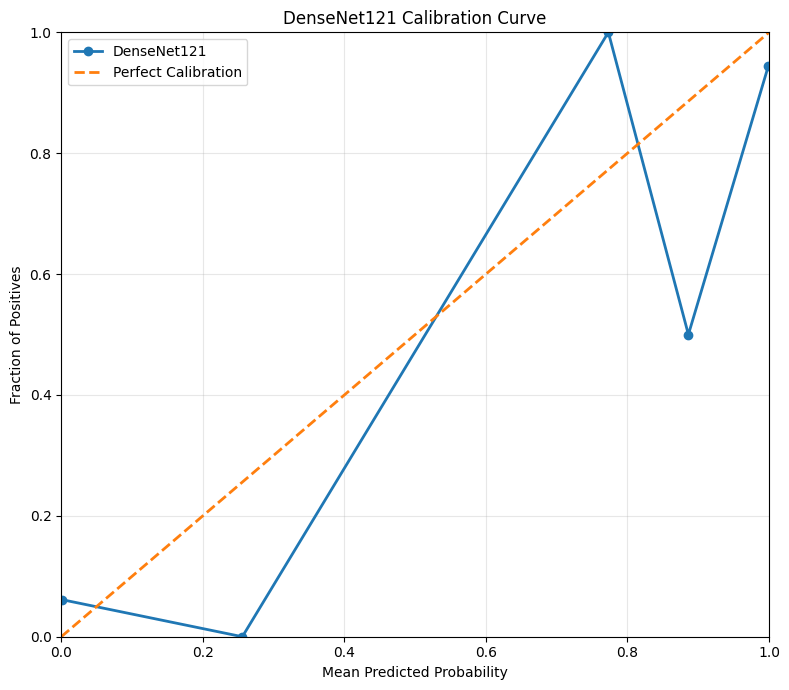

✅ Calibration curve saved to:
/content/drive/MyDrive/Classification/Results/DenseNet121/Calibration_analysis/DenseNet121_calibration_curve_epoch_25.png


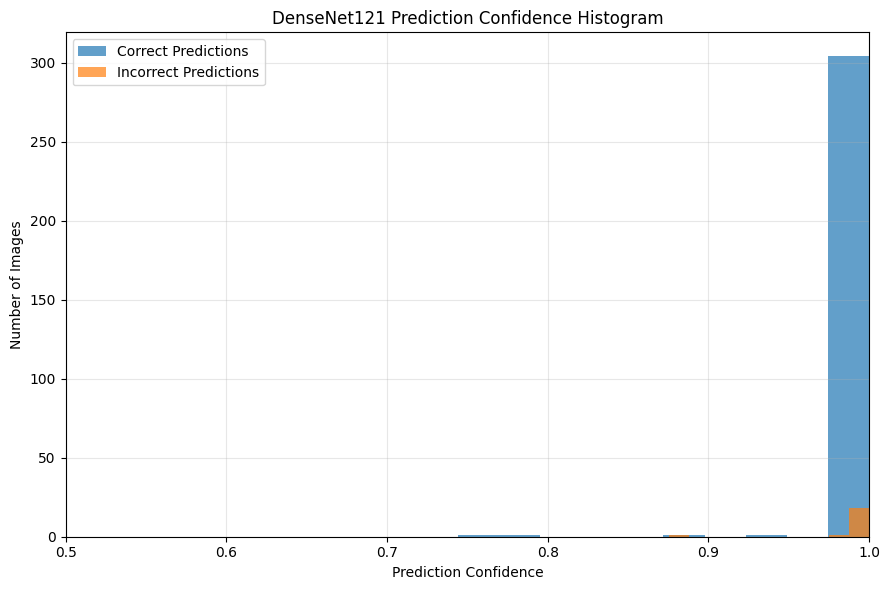

✅ Confidence histogram saved to:
/content/drive/MyDrive/Classification/Results/DenseNet121/Calibration_analysis/DenseNet121_confidence_histogram_epoch_25.png


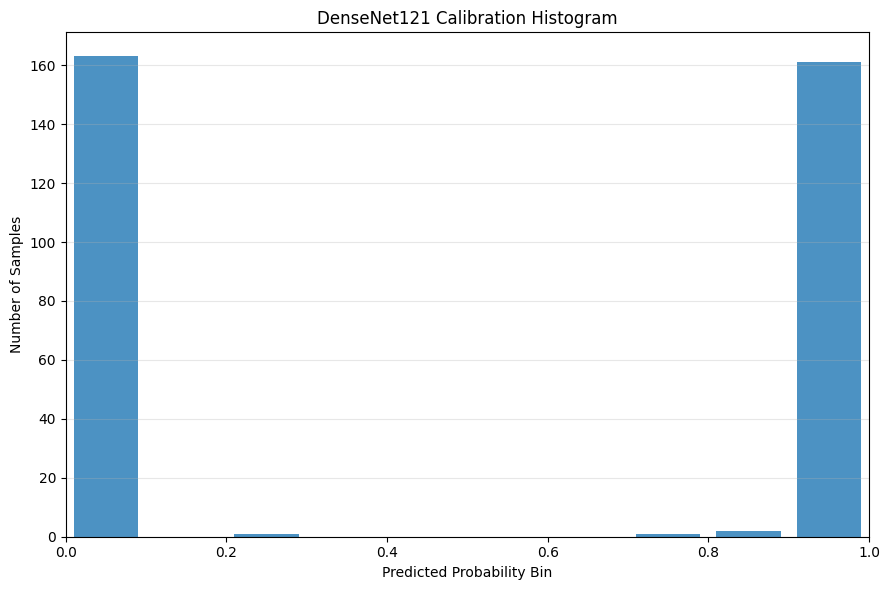

✅ Calibration histogram saved to:
/content/drive/MyDrive/Classification/Results/DenseNet121/Calibration_analysis/DenseNet121_calibration_histogram_epoch_25.png


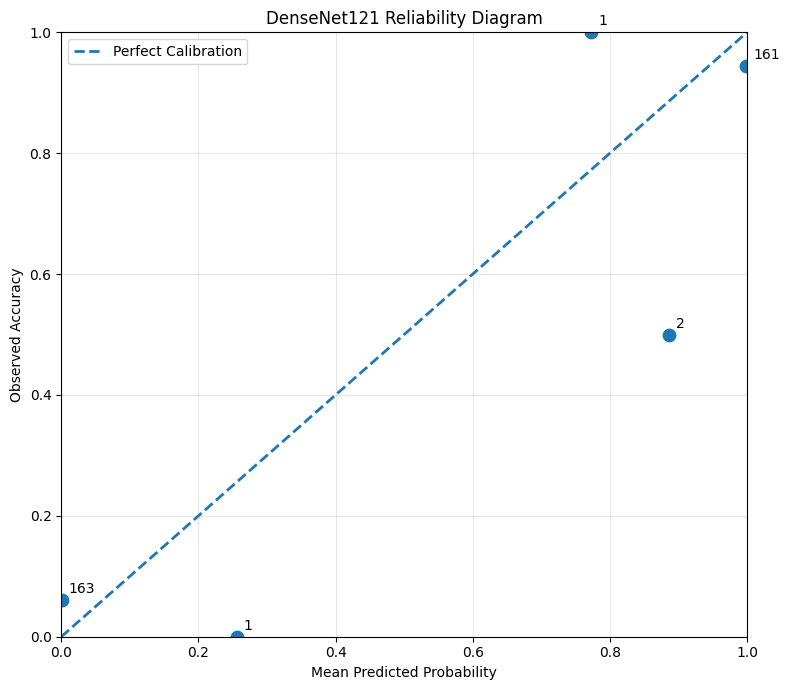

✅ Reliability diagram saved to:
/content/drive/MyDrive/Classification/Results/DenseNet121/Calibration_analysis/DenseNet121_reliability_diagram_epoch_25.png


EVALUATION COMPLETE
Model: DenseNet121
Weights: epoch_25_weights.pth
Test directory: /content/drive/MyDrive/Classification/Bt_training_and_testing/Testing_resized_v2
Total samples: 328

Classification:
Accuracy    = 0.9390
Sensitivity = 0.9390
Specificity = 0.9390
Precision   = 0.9390
F1-score    = 0.9390

Calibration:
Brier Score = 0.060456
ECE         = 0.060823
MCE         = 0.386104

95% CIs:
Accuracy    = 0.9077–0.9602
Sensitivity = 0.8914–0.9665
Specificity = 0.8914–0.9665
Precision   = 0.8914–0.9665
Brier       = 0.036220–0.087866
ECE         = 0.036284–0.087808
MCE         = 0.103567–0.875776


In [5]:
# ============================================================
# DENSENET121 COMPLETE TEST EVALUATION
#
# Includes:
#   1. TP, FP, TN, FN
#   2. Accuracy
#   3. Sensitivity
#   4. Specificity
#   5. Precision
#   6. F1-score
#   7. Accuracy StdDev
#   8. 95% CI - Accuracy
#   9. 95% CI - Sensitivity
#  10. 95% CI - Specificity
#  11. 95% CI - Precision
#  12. Brier Score
#  13. Expected Calibration Error (ECE)
#  14. Maximum Calibration Error (MCE)
#  15. Calibration Curve
#  16. Confidence Histogram
#  17. Calibration Histogram
#  18. Bootstrap 95% CI - Brier Score
#  19. Bootstrap 95% CI - ECE
#  20. Bootstrap 95% CI - MCE
#  21. Detailed prediction CSV
#  22. Calibration-bin CSV
# ============================================================


# ============================================================
# IMPORTS
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torchvision.models import (
    densenet121,
    DenseNet121_Weights
)

from torchvision.io import read_image

from tqdm import tqdm


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ============================================================
# 2. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


# ============================================================
# 3. PATHS
# ============================================================

weights_path = (
    "/content/drive/MyDrive/"
    "Classification/Weights/"
    "DenseNet121/"
    "epoch_25_weights.pth"
)

test_root = (
    "/content/drive/MyDrive/"
    "Classification/Bt_training_and_testing/"
    "Testing_resized_v2"
)

output_dir = (
    "/content/drive/MyDrive/"
    "Classification/Results/"
    "DenseNet121/Calibration_analysis"
)

os.makedirs(output_dir, exist_ok=True)


# ============================================================
# 4. MODEL
# ============================================================

weights = DenseNet121_Weights.DEFAULT

transform = weights.transforms()


class DenseNetBinary(nn.Module):

    def __init__(self):

        super().__init__()

        self.model = densenet121(
            weights=weights
        )

        in_features = (
            self.model.classifier.in_features
        )

        self.model.classifier = nn.Sequential(
            nn.Linear(
                in_features,
                1
            ),
            nn.Sigmoid()
        )

    def forward(self, x):

        return self.model(x)


# ============================================================
# 5. LOAD MODEL
# ============================================================

model = DenseNetBinary().to(device)


print("\nLoading DenseNet weights:")
print(weights_path)

checkpoint = torch.load(
    weights_path,
    map_location=device
)

# Handle both normal state_dict and
# possible checkpoint dictionaries
if isinstance(checkpoint, dict):

    if "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]

    elif "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]

    else:
        state_dict = checkpoint

else:
    state_dict = checkpoint


# Remove possible "module." prefix
clean_state_dict = {}

for key, value in state_dict.items():

    new_key = key

    if new_key.startswith("module."):
        new_key = new_key[7:]

    clean_state_dict[new_key] = value


model.load_state_dict(
    clean_state_dict,
    strict=True
)

model.eval()

print("✅ DenseNet121 weights loaded successfully.")


# ============================================================
# 6. CLASS MAPPING
# ============================================================

class_map = {
    "a_non_cancer": 0,
    "b_cancer": 1
}


# ============================================================
# 7. HELPER: WILSON 95% CI
# ============================================================

def wilson_ci(
    successes,
    total,
    confidence=0.95
):

    if total == 0:

        return 0.0, 0.0

    # 95% z-score
    z = 1.959963984540054

    p = successes / total

    denominator = (
        1 +
        (z ** 2) / total
    )

    center = (
        p +
        (z ** 2) / (2 * total)
    ) / denominator

    margin = (
        z *
        np.sqrt(
            (
                p * (1 - p) / total
            ) +
            (
                z ** 2 /
                (4 * total ** 2)
            )
        )
        / denominator
    )

    lower = center - margin
    upper = center + margin

    lower = max(0.0, lower)
    upper = min(1.0, upper)

    return lower, upper


# ============================================================
# 8. CALIBRATION METRICS
# ============================================================

def calculate_calibration_metrics(
    y_true,
    probabilities,
    n_bins=10
):

    y_true = np.asarray(
        y_true,
        dtype=float
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float
    )

    # --------------------------------------------------------
    # Brier Score
    # --------------------------------------------------------

    brier_score = np.mean(
        (probabilities - y_true) ** 2
    )

    # --------------------------------------------------------
    # ECE and MCE
    # --------------------------------------------------------

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    bin_data = []

    ece = 0.0
    mce = 0.0

    n = len(y_true)

    for i in range(n_bins):

        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i == n_bins - 1:

            mask = (
                (probabilities >= lower) &
                (probabilities <= upper)
            )

        else:

            mask = (
                (probabilities >= lower) &
                (probabilities < upper)
            )

        count = np.sum(mask)

        if count > 0:

            mean_confidence = np.mean(
                probabilities[mask]
            )

            mean_accuracy = np.mean(
                y_true[mask]
            )

            calibration_error = abs(
                mean_accuracy -
                mean_confidence
            )

            bin_weight = count / n

            ece += (
                bin_weight *
                calibration_error
            )

            mce = max(
                mce,
                calibration_error
            )

        else:

            mean_confidence = np.nan
            mean_accuracy = np.nan
            calibration_error = np.nan

        bin_data.append({

            "Bin": i + 1,

            "Bin_Lower":
                lower,

            "Bin_Upper":
                upper,

            "Count":
                int(count),

            "Mean_Confidence":
                mean_confidence,

            "Mean_Accuracy":
                mean_accuracy,

            "Calibration_Error":
                calibration_error

        })

    bin_df = pd.DataFrame(
        bin_data
    )

    return (
        brier_score,
        ece,
        mce,
        bin_df
    )


# ============================================================
# 9. BOOTSTRAP CONFIDENCE INTERVAL
# ============================================================

def bootstrap_ci(
    y_true,
    probabilities,
    metric_function,
    n_bootstrap=2000,
    confidence=0.95,
    seed=42
):

    rng = np.random.default_rng(seed)

    y_true = np.asarray(
        y_true
    )

    probabilities = np.asarray(
        probabilities
    )

    n = len(y_true)

    bootstrap_values = []

    for _ in tqdm(
        range(n_bootstrap),
        desc="Bootstrap CI"
    ):

        indices = rng.integers(
            0,
            n,
            size=n
        )

        y_sample = y_true[
            indices
        ]

        p_sample = probabilities[
            indices
        ]

        try:

            value = metric_function(
                y_sample,
                p_sample
            )

            bootstrap_values.append(
                value
            )

        except Exception:

            continue

    bootstrap_values = np.asarray(
        bootstrap_values
    )

    alpha = 1.0 - confidence

    lower = np.percentile(
        bootstrap_values,
        100 * (alpha / 2)
    )

    upper = np.percentile(
        bootstrap_values,
        100 * (1 - alpha / 2)
    )

    return (
        lower,
        upper,
        bootstrap_values
    )


# ============================================================
# 10. COLLECT PREDICTIONS
# ============================================================

TP = 0
FP = 0
TN = 0
FN = 0

accuracies = []

all_predictions = []
all_labels = []
all_probabilities = []
all_filenames = []
all_class_names = []


print("\n" + "=" * 70)
print("STARTING TEST EVALUATION")
print("=" * 70)


with torch.no_grad():

    for cls_name, label in class_map.items():

        folder = os.path.join(
            test_root,
            cls_name
        )

        if not os.path.exists(folder):

            print(
                f"⚠️ Folder does not exist: {folder}"
            )

            continue

        filenames = sorted(
            os.listdir(folder)
        )

        for fname in tqdm(
            filenames,
            desc=f"Evaluating {cls_name}"
        ):

            if not fname.lower().endswith(
                (
                    ".png",
                    ".jpg",
                    ".jpeg"
                )
            ):

                continue

            path = os.path.join(
                folder,
                fname
            )

            try:

                # ------------------------------------------------
                # Read image
                # ------------------------------------------------

                image = read_image(
                    path
                ).float() / 255.0

                # ------------------------------------------------
                # Ensure 3 channels
                # ------------------------------------------------

                if image.shape[0] == 1:

                    image = image.repeat(
                        3,
                        1,
                        1
                    )

                elif image.shape[0] > 3:

                    image = image[:3]

                # ------------------------------------------------
                # Transform
                # ------------------------------------------------

                image = transform(
                    image
                )

                image = image.unsqueeze(
                    0
                ).to(device)

                # ------------------------------------------------
                # Prediction
                # ------------------------------------------------

                output = model(
                    image
                )

                probability = (
                    output.squeeze().item()
                )

                probability = float(
                    np.clip(
                        probability,
                        0.0,
                        1.0
                    )
                )

                pred = (
                    1
                    if probability >= 0.5
                    else 0
                )

                # ------------------------------------------------
                # Store results
                # ------------------------------------------------

                all_predictions.append(
                    pred
                )

                all_labels.append(
                    label
                )

                all_probabilities.append(
                    probability
                )

                all_filenames.append(
                    fname
                )

                all_class_names.append(
                    cls_name
                )

                # ------------------------------------------------
                # Accuracy deviation
                # ------------------------------------------------

                correct = (
                    pred == label
                )

                accuracies.append(
                    int(correct)
                )

                # ------------------------------------------------
                # Confusion matrix
                # ------------------------------------------------

                if pred == 1 and label == 1:

                    TP += 1

                elif pred == 1 and label == 0:

                    FP += 1

                elif pred == 0 and label == 0:

                    TN += 1

                elif pred == 0 and label == 1:

                    FN += 1

            except Exception as e:

                print(
                    f"\n⚠️ Error processing "
                    f"{fname}: {e}"
                )

                continue


# ============================================================
# 11. CONVERT TO NUMPY
# ============================================================

all_labels = np.asarray(
    all_labels,
    dtype=int
)

all_predictions = np.asarray(
    all_predictions,
    dtype=int
)

all_probabilities = np.asarray(
    all_probabilities,
    dtype=float
)

accuracies = np.asarray(
    accuracies,
    dtype=int
)


# ============================================================
# 12. BASIC METRICS
# ============================================================

total = (
    TP +
    FP +
    TN +
    FN
)

# EXACT formulas requested
accuracy = (
    (TP + TN) / total
    if total
    else 0
)

sensitivity = (
    TP / (TP + FN)
    if (TP + FN)
    else 0
)

specificity = (
    TN / (TN + FP)
    if (TN + FP)
    else 0
)

precision = (
    TP / (TP + FP)
    if (TP + FP)
    else 0
)

f1_score = (
    2 *
    precision *
    sensitivity /
    (precision + sensitivity)
    if (precision + sensitivity)
    else 0
)

accuracy_std = (
    np.std(accuracies)
    if len(accuracies)
    else 0
)


# ============================================================
# 13. WILSON 95% CIs
# ============================================================

accuracy_ci_lower, accuracy_ci_upper = wilson_ci(
    TP + TN,
    total
)

sensitivity_ci_lower, sensitivity_ci_upper = wilson_ci(
    TP,
    TP + FN
)

specificity_ci_lower, specificity_ci_upper = wilson_ci(
    TN,
    TN + FP
)

precision_ci_lower, precision_ci_upper = wilson_ci(
    TP,
    TP + FP
)


# ============================================================
# 14. CALIBRATION METRICS
# ============================================================

(
    brier_score,
    ece,
    mce,
    calibration_df
) = calculate_calibration_metrics(
    all_labels,
    all_probabilities,
    n_bins=10
)


# ============================================================
# 15. BOOTSTRAP BRIER SCORE
# ============================================================

def brier_metric(
    y,
    p
):

    return np.mean(
        (p - y) ** 2
    )


print("\nCalculating bootstrap CI for Brier Score...")

brier_ci_lower, brier_ci_upper, _ = bootstrap_ci(
    all_labels,
    all_probabilities,
    brier_metric,
    n_bootstrap=2000,
    confidence=0.95,
    seed=42
)


# ============================================================
# 16. BOOTSTRAP ECE
# ============================================================

def ece_metric(
    y,
    p
):

    _, ece_value, _, _ = calculate_calibration_metrics(
        y,
        p,
        n_bins=10
    )

    return ece_value


print("\nCalculating bootstrap CI for ECE...")

ece_ci_lower, ece_ci_upper, _ = bootstrap_ci(
    all_labels,
    all_probabilities,
    ece_metric,
    n_bootstrap=2000,
    confidence=0.95,
    seed=43
)


# ============================================================
# 17. BOOTSTRAP MCE
# ============================================================

def mce_metric(
    y,
    p
):

    _, _, mce_value, _ = calculate_calibration_metrics(
        y,
        p,
        n_bins=10
    )

    return mce_value


print("\nCalculating bootstrap CI for MCE...")

mce_ci_lower, mce_ci_upper, _ = bootstrap_ci(
    all_labels,
    all_probabilities,
    mce_metric,
    n_bootstrap=2000,
    confidence=0.95,
    seed=44
)


# ============================================================
# 18. PRINT CONFUSION MATRIX
# ============================================================

print("\n")
print("=" * 70)
print("DENSENET121 TEST RESULTS")
print("=" * 70)

print(
    f"Total Images Tested: {total}"
)

print("\nConfusion Matrix:")

print(
    f"  True Positives (TP):  {TP}"
)

print(
    f"  False Positives (FP): {FP}"
)

print(
    f"  True Negatives (TN):  {TN}"
)

print(
    f"  False Negatives (FN): {FN}"
)


# ============================================================
# 19. PRINT PERFORMANCE METRICS
# ============================================================

print("\nPerformance Metrics:")

print(
    f"  Accuracy:     "
    f"{accuracy:.4f} "
    f"({accuracy * 100:.2f}%)"
)

print(
    f"  Sensitivity:  "
    f"{sensitivity:.4f} "
    f"({sensitivity * 100:.2f}%)"
)

print(
    f"  Specificity:  "
    f"{specificity:.4f} "
    f"({specificity * 100:.2f}%)"
)

print(
    f"  Precision:    "
    f"{precision:.4f} "
    f"({precision * 100:.2f}%)"
)

print(
    f"  F1-Score:     "
    f"{f1_score:.4f}"
)

print(
    f"  Accuracy StdDev: "
    f"{accuracy_std:.4f}"
)


# ============================================================
# 20. PRINT CONFIDENCE INTERVALS
# ============================================================

print("\n95% Confidence Intervals:")

print(
    f"  Accuracy:     "
    f"{accuracy_ci_lower:.4f} - "
    f"{accuracy_ci_upper:.4f}"
)

print(
    f"  Sensitivity:  "
    f"{sensitivity_ci_lower:.4f} - "
    f"{sensitivity_ci_upper:.4f}"
)

print(
    f"  Specificity:  "
    f"{specificity_ci_lower:.4f} - "
    f"{specificity_ci_upper:.4f}"
)

print(
    f"  Precision:    "
    f"{precision_ci_lower:.4f} - "
    f"{precision_ci_upper:.4f}"
)


# ============================================================
# 21. PRINT CALIBRATION METRICS
# ============================================================

print("\nCalibration Metrics:")

print(
    f"  Brier Score: "
    f"{brier_score:.6f}"
)

print(
    f"  Brier 95% CI: "
    f"{brier_ci_lower:.6f} - "
    f"{brier_ci_upper:.6f}"
)

print(
    f"  ECE:          "
    f"{ece:.6f}"
)

print(
    f"  ECE 95% CI:   "
    f"{ece_ci_lower:.6f} - "
    f"{ece_ci_upper:.6f}"
)

print(
    f"  MCE:          "
    f"{mce:.6f}"
)

print(
    f"  MCE 95% CI:   "
    f"{mce_ci_lower:.6f} - "
    f"{mce_ci_upper:.6f}"
)

print("=" * 70)


# ============================================================
# 22. PRINT CALIBRATION TABLE
# ============================================================

print("\nCalibration Bins:")
print(
    calibration_df.to_string(
        index=False
    )
)


# ============================================================
# 23. SAVE CALIBRATION BIN DATA
# ============================================================

calibration_csv = os.path.join(
    output_dir,
    "DenseNet121_calibration_bins_epoch_25.csv"
)

calibration_df.to_csv(
    calibration_csv,
    index=False
)

print(
    f"\n✅ Calibration-bin data saved to:\n"
    f"{calibration_csv}"
)


# ============================================================
# 24. SAVE MAIN METRICS CSV
# ============================================================

results = {

    "Model": [
        "DenseNet121"
    ],

    "TP": [TP],

    "FP": [FP],

    "TN": [TN],

    "FN": [FN],

    "Total": [total],

    "Accuracy": [
        round(accuracy, 4)
    ],

    "Accuracy_CI_Lower": [
        round(
            accuracy_ci_lower,
            4
        )
    ],

    "Accuracy_CI_Upper": [
        round(
            accuracy_ci_upper,
            4
        )
    ],

    "Accuracy_95CI": [
        f"{accuracy_ci_lower:.4f} - "
        f"{accuracy_ci_upper:.4f}"
    ],

    "Sensitivity": [
        round(
            sensitivity,
            4
        )
    ],

    "Sensitivity_CI_Lower": [
        round(
            sensitivity_ci_lower,
            4
        )
    ],

    "Sensitivity_CI_Upper": [
        round(
            sensitivity_ci_upper,
            4
        )
    ],

    "Sensitivity_95CI": [
        f"{sensitivity_ci_lower:.4f} - "
        f"{sensitivity_ci_upper:.4f}"
    ],

    "Specificity": [
        round(
            specificity,
            4
        )
    ],

    "Specificity_CI_Lower": [
        round(
            specificity_ci_lower,
            4
        )
    ],

    "Specificity_CI_Upper": [
        round(
            specificity_ci_upper,
            4
        )
    ],

    "Specificity_95CI": [
        f"{specificity_ci_lower:.4f} - "
        f"{specificity_ci_upper:.4f}"
    ],

    "Precision": [
        round(
            precision,
            4
        )
    ],

    "Precision_CI_Lower": [
        round(
            precision_ci_lower,
            4
        )
    ],

    "Precision_CI_Upper": [
        round(
            precision_ci_upper,
            4
        )
    ],

    "Precision_95CI": [
        f"{precision_ci_lower:.4f} - "
        f"{precision_ci_upper:.4f}"
    ],

    "F1_Score": [
        round(
            f1_score,
            4
        )
    ],

    "Accuracy_StdDev": [
        round(
            accuracy_std,
            4
        )
    ],

    # Calibration
    "Brier_Score": [
        round(
            brier_score,
            6
        )
    ],

    "Brier_CI_Lower": [
        round(
            brier_ci_lower,
            6
        )
    ],

    "Brier_CI_Upper": [
        round(
            brier_ci_upper,
            6
        )
    ],

    "Brier_95CI": [
        f"{brier_ci_lower:.6f} - "
        f"{brier_ci_upper:.6f}"
    ],

    "ECE": [
        round(
            ece,
            6
        )
    ],

    "ECE_CI_Lower": [
        round(
            ece_ci_lower,
            6
        )
    ],

    "ECE_CI_Upper": [
        round(
            ece_ci_upper,
            6
        )
    ],

    "ECE_95CI": [
        f"{ece_ci_lower:.6f} - "
        f"{ece_ci_upper:.6f}"
    ],

    "MCE": [
        round(
            mce,
            6
        )
    ],

    "MCE_CI_Lower": [
        round(
            mce_ci_lower,
            6
        )
    ],

    "MCE_CI_Upper": [
        round(
            mce_ci_upper,
            6
        )
    ],

    "MCE_95CI": [
        f"{mce_ci_lower:.6f} - "
        f"{mce_ci_upper:.6f}"
    ]
}


results_df = pd.DataFrame(
    results
)


metrics_csv = os.path.join(
    output_dir,
    "DenseNet121_complete_metrics_epoch_25.csv"
)

results_df.to_csv(
    metrics_csv,
    index=False
)

print(
    f"\n✅ Complete metrics saved to:\n"
    f"{metrics_csv}"
)


# ============================================================
# 25. SAVE DETAILED PREDICTIONS
# ============================================================

detailed_results = pd.DataFrame({

    "Filename":
        all_filenames,

    "Class":
        all_class_names,

    "True_Label":
        all_labels,

    "Predicted_Label":
        all_predictions,

    "Probability_Cancer":
        all_probabilities,

    "Predicted_Confidence":
        np.maximum(
            all_probabilities,
            1 - all_probabilities
        ),

    "Correct":
        (
            all_predictions ==
            all_labels
        ).astype(int)

})


detailed_csv = os.path.join(
    output_dir,
    "DenseNet121_detailed_predictions_epoch_25.csv"
)

detailed_results.to_csv(
    detailed_csv,
    index=False
)

print(
    f"✅ Detailed predictions saved to:\n"
    f"{detailed_csv}"
)


# ============================================================
# 26. CALIBRATION CURVE
# ============================================================

plt.figure(
    figsize=(8, 7)
)

valid_bins = calibration_df[
    calibration_df["Count"] > 0
]

plt.plot(
    valid_bins["Mean_Confidence"],
    valid_bins["Mean_Accuracy"],
    marker="o",
    linewidth=2,
    label="DenseNet121"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=2,
    label="Perfect Calibration"
)

plt.xlabel(
    "Mean Predicted Probability"
)

plt.ylabel(
    "Fraction of Positives"
)

plt.title(
    "DenseNet121 Calibration Curve"
)

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

calibration_plot = os.path.join(
    output_dir,
    "DenseNet121_calibration_curve_epoch_25.png"
)

plt.savefig(
    calibration_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"✅ Calibration curve saved to:\n"
    f"{calibration_plot}"
)


# ============================================================
# 27. CONFIDENCE HISTOGRAM
# ============================================================

confidence = np.maximum(
    all_probabilities,
    1 - all_probabilities
)

correct_mask = (
    all_predictions ==
    all_labels
)

incorrect_mask = ~correct_mask


plt.figure(
    figsize=(9, 6)
)

plt.hist(
    confidence[correct_mask],
    bins=10,
    alpha=0.7,
    label="Correct Predictions"
)

plt.hist(
    confidence[incorrect_mask],
    bins=10,
    alpha=0.7,
    label="Incorrect Predictions"
)

plt.xlabel(
    "Prediction Confidence"
)

plt.ylabel(
    "Number of Images"
)

plt.title(
    "DenseNet121 Prediction Confidence Histogram"
)

plt.xlim(
    0.5,
    1.0
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

confidence_plot = os.path.join(
    output_dir,
    "DenseNet121_confidence_histogram_epoch_25.png"
)

plt.savefig(
    confidence_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"✅ Confidence histogram saved to:\n"
    f"{confidence_plot}"
)


# ============================================================
# 28. CALIBRATION BIN HISTOGRAM
# ============================================================

plt.figure(
    figsize=(9, 6)
)

bin_centers = (
    calibration_df["Bin_Lower"] +
    calibration_df["Bin_Upper"]
) / 2

plt.bar(
    bin_centers,
    calibration_df["Count"],
    width=0.08,
    alpha=0.8
)

plt.xlabel(
    "Predicted Probability Bin"
)

plt.ylabel(
    "Number of Samples"
)

plt.title(
    "DenseNet121 Calibration Histogram"
)

plt.xlim(
    0,
    1
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

calibration_histogram = os.path.join(
    output_dir,
    "DenseNet121_calibration_histogram_epoch_25.png"
)

plt.savefig(
    calibration_histogram,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"✅ Calibration histogram saved to:\n"
    f"{calibration_histogram}"
)


# ============================================================
# 29. RELIABILITY DIAGRAM WITH BIN COUNTS
# ============================================================

plt.figure(
    figsize=(8, 7)
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=2,
    label="Perfect Calibration"
)

plt.scatter(
    valid_bins["Mean_Confidence"],
    valid_bins["Mean_Accuracy"],
    s=80
)

for _, row in valid_bins.iterrows():

    plt.annotate(
        str(int(row["Count"])),
        (
            row["Mean_Confidence"],
            row["Mean_Accuracy"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel(
    "Mean Predicted Probability"
)

plt.ylabel(
    "Observed Accuracy"
)

plt.title(
    "DenseNet121 Reliability Diagram"
)

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.tight_layout()

reliability_plot = os.path.join(
    output_dir,
    "DenseNet121_reliability_diagram_epoch_25.png"
)

plt.savefig(
    reliability_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"✅ Reliability diagram saved to:\n"
    f"{reliability_plot}"
)


# ============================================================
# 30. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("EVALUATION COMPLETE")
print("=" * 70)

print(
    f"Model: DenseNet121"
)

print(
    f"Weights: epoch_25_weights.pth"
)

print(
    f"Test directory: {test_root}"
)

print(
    f"Total samples: {total}"
)

print("\nClassification:")

print(
    f"Accuracy    = {accuracy:.4f}"
)

print(
    f"Sensitivity = {sensitivity:.4f}"
)

print(
    f"Specificity = {specificity:.4f}"
)

print(
    f"Precision   = {precision:.4f}"
)

print(
    f"F1-score    = {f1_score:.4f}"
)

print("\nCalibration:")

print(
    f"Brier Score = {brier_score:.6f}"
)

print(
    f"ECE         = {ece:.6f}"
)

print(
    f"MCE         = {mce:.6f}"
)

print("\n95% CIs:")

print(
    f"Accuracy    = "
    f"{accuracy_ci_lower:.4f}–"
    f"{accuracy_ci_upper:.4f}"
)

print(
    f"Sensitivity = "
    f"{sensitivity_ci_lower:.4f}–"
    f"{sensitivity_ci_upper:.4f}"
)

print(
    f"Specificity = "
    f"{specificity_ci_lower:.4f}–"
    f"{specificity_ci_upper:.4f}"
)

print(
    f"Precision   = "
    f"{precision_ci_lower:.4f}–"
    f"{precision_ci_upper:.4f}"
)

print(
    f"Brier       = "
    f"{brier_ci_lower:.6f}–"
    f"{brier_ci_upper:.6f}"
)

print(
    f"ECE         = "
    f"{ece_ci_lower:.6f}–"
    f"{ece_ci_upper:.6f}"
)

print(
    f"MCE         = "
    f"{mce_ci_lower:.6f}–"
    f"{mce_ci_upper:.6f}"
)

print("=" * 70)